In [73]:
# Importicificacion de librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/test.csv")
df_muestra = df.sample(
    n=min(1000000, len(df)),
    random_state=42
)

# Variable objetivo
target = "TestScore_Math"

# Variables predictoras (Post analisis de sesgo)
variables = [
    "Age", "Grade", "AttendanceRate",
    "StudyHours", "InternetAccess",
    "Extracurricular", "PartTimeJob",
    "ParentSupport", "Romantic",
    "FreeTime", "GoOut"
]

# X E Y
X = df_muestra[variables]
y = df_muestra[target]

print("Dimensiones:", X.shape)
print("Valores nulos:", df_muestra.isnull().sum().sum())
print("Valores repetidos:", df_muestra.duplicated().sum())

Dimensiones: (999997, 11)
Valores nulos: 0
Valores repetidos: 0


In [74]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Separar variables numéricas y categóricas
numericas = X.select_dtypes(include=["int64", "float64"]).columns
categoricas = X.select_dtypes(include=["object"]).columns

# Transformaciones
preprocesamiento = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categoricas)
    ]
)

# Separar entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (799997, 11)
Prueba: (200000, 11)


In [75]:
X

,Age,Grade,AttendanceRate,StudyHours,InternetAccess,Extracurricular,PartTimeJob,ParentSupport,Romantic,FreeTime,GoOut
481649,14,9,0.877542,0.867658,1,0,0,0,0,3,1
79954,17,12,0.941053,1.064801,1,0,0,0,1,5,2
848133,15,10,0.937765,1.230326,1,1,1,1,0,2,1
500890,16,11,0.986277,1.430056,1,0,0,0,0,3,2
55399,18,12,0.906577,1.077844,1,1,0,1,0,1,3
...,...,...,...,...,...,...,...,...,...,...,...
259178,15,10,0.977432,1.281426,1,0,0,1,0,4,3
365838,16,11,0.815388,0.686736,0,0,0,0,0,5,3
131932,16,11,0.930896,0.804310,1,0,0,0,0,3,2
671155,15,10,0.904342,1.187345,1,1,0,1,0,3,1


In [76]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.tree import DecisionTreeRegressor

#Definir modelos a probar
modelos = {

    "Regresión Lineal": LinearRegression(),

    "Lasso (L1)": Lasso(alpha=1.0, max_iter=2000),

    "Ridge (L2)": Ridge(alpha=1.0),

    "Árbol de Decisión (Reg)": DecisionTreeRegressor(max_depth=10, random_state=42),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=16,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    ),

    "Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=150,
        max_leaf_nodes=31,
        learning_rate=0.1,
        l2_regularization=1.0,
        random_state=42
    )
}

resultados = []
modelos_entrenados = {}

# Entrenamiento de modelos
for nombre, modelo in modelos.items():

    pipeline = Pipeline([
        ("preprocesamiento", preprocesamiento),
        ("modelo", modelo)
    ])

    print("Entrenando:", nombre)

    pipeline.fit(X_train, y_train)

    predicciones = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predicciones)
    mse = mean_squared_error(y_test, predicciones)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predicciones)

    resultados.append({
        "Modelo": nombre,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

    modelos_entrenados[nombre] = pipeline

#Resultados del entrenamiento
df_resultados = pd.DataFrame(resultados)

df_resultados = df_resultados.sort_values(
    by="RMSE",
    ascending=True
)

display(df_resultados)

Entrenando: Regresión Lineal
Entrenando: Lasso (L1)
Entrenando: Ridge (L2)
Entrenando: Árbol de Decisión (Reg)
Entrenando: Random Forest
Entrenando: Gradient Boosting


,Modelo,MAE,MSE,RMSE,R2
5,Gradient Boosting,4.544850,32.426421,5.694420,0.672566
0,Regresión Lineal,4.548276,32.447040,5.696230,0.672358
2,Ridge (L2),4.548276,32.447040,5.696230,0.672358
4,Random Forest,4.558740,32.625204,5.711848,0.670559
3,Árbol de Decisión (Reg),4.558748,32.644032,5.713496,0.670369
1,Lasso (L1),4.648729,33.801392,5.813896,0.658682


In [77]:
display(df_resultados.style.highlight_max(color='green', axis=0).highlight_min(color='red', axis=0))

,Modelo,MAE,MSE,RMSE,R2
5,Gradient Boosting,4.544850,32.426421,5.694420,0.672566
0,Regresión Lineal,4.548276,32.447040,5.696230,0.672358
2,Ridge (L2),4.548276,32.447040,5.696230,0.672358
4,Random Forest,4.558740,32.625204,5.711848,0.670559
3,Árbol de Decisión (Reg),4.558748,32.644032,5.713496,0.670369
1,Lasso (L1),4.648729,33.801392,5.813896,0.658682


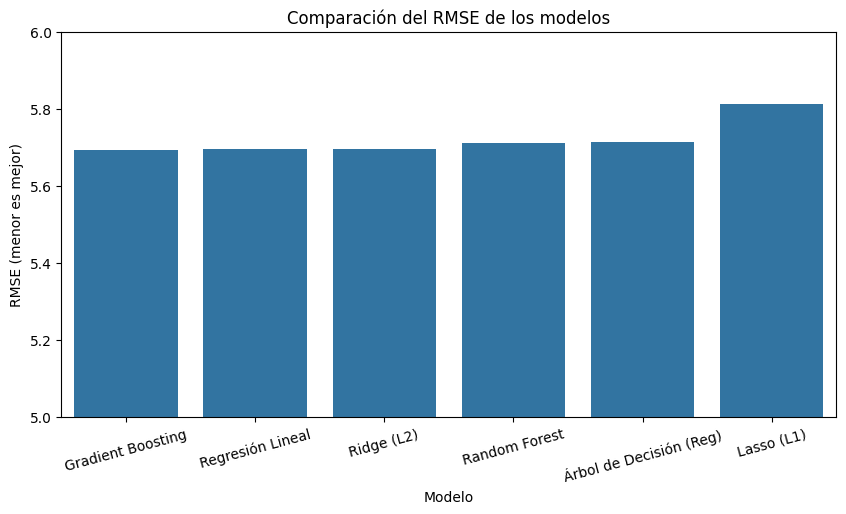

In [78]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_resultados,
    x="Modelo",
    y="RMSE"
)

plt.title("Comparación del RMSE de los modelos")
plt.xlabel("Modelo")
plt.ylabel("RMSE (menor es mejor)")
plt.xticks(rotation=15)
plt.ylim(5,6)
plt.show()

In [79]:
from sklearn.inspection import permutation_importance

# Seleccionar el mejor modelo
mejor_nombre = df_resultados.iloc[0]["Modelo"]
mejor_modelo = modelos_entrenados[mejor_nombre]

print("Mejor modelo:", mejor_nombre)

# Utilizar una muestra para acelerar el cálculo
X_muestra = X_test.sample(
    n=min(10000, len(X_test)),
    random_state=42
)

y_muestra = y_test.loc[X_muestra.index]

importancia = permutation_importance(
    mejor_modelo,
    X_muestra,
    y_muestra,
    n_repeats=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1
)

df_importancia = pd.DataFrame({
    "Variable": variables,
    "Importancia": importancia.importances_mean,
    "Desviacion": importancia.importances_std
})

df_importancia = df_importancia.sort_values(
    by="Importancia",
    ascending=False
)

display(df_importancia)

Mejor modelo: Gradient Boosting


,Variable,Importancia,Desviacion
2,AttendanceRate,6.353218,0.054372
3,StudyHours,0.141797,0.005859
6,PartTimeJob,0.000422,0.000403
9,FreeTime,0.000204,0.000324
8,Romantic,0.000196,0.000096
10,GoOut,0.000159,0.000524
4,InternetAccess,0.000108,0.000223
5,Extracurricular,0.000029,0.000194
1,Grade,0.000000,0.000000
7,ParentSupport,-0.000115,0.000132


Para esto, buscamos el mejor resultado en los siguientes puntos:
- RMSE mas bajo: Gradient Boosting
- R2 mas alto: Gradient Boosting

Gradient Boosting obtiene el mejor resultado general, por lo cual es recomendable usar como modelo.

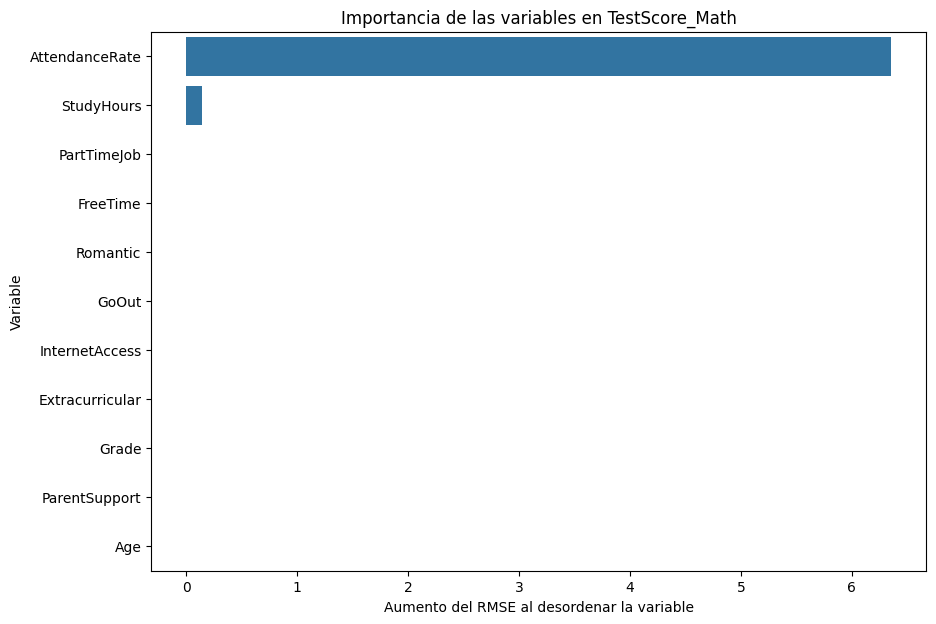

In [80]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=df_importancia,
    x="Importancia",
    y="Variable"
)

plt.title("Importancia de las variables en TestScore_Math")
plt.xlabel("Aumento del RMSE al desordenar la variable")
plt.ylabel("Variable")
plt.show()

Se puede apreciar como las unicas variables que realmente influyen significativamente en las notas de matematicas son significativamente el ratio de asistencia y muy por debajo las horas de estudio

Variables analizadas: ['AttendanceRate', 'StudyHours', 'PartTimeJob', 'FreeTime', 'Romantic']


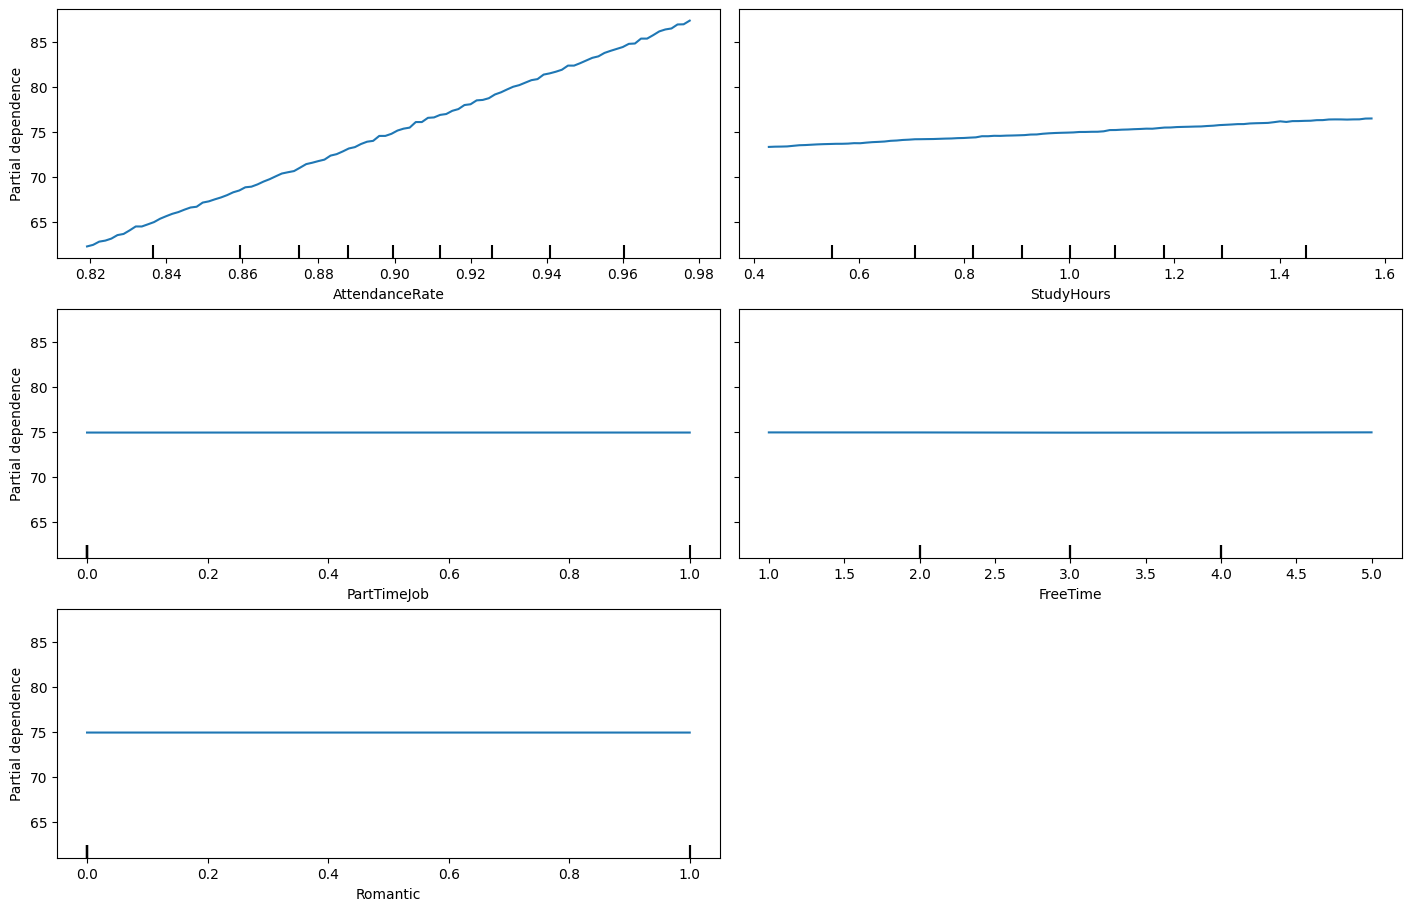

In [81]:
from sklearn.inspection import PartialDependenceDisplay

# Seleccionar les variables numéricas más importantes
top_variables = [
    v for v in df_importancia["Variable"]
    if v in numericas
][:5]

print("Variables analizadas:", top_variables)

fig, ax = plt.subplots(
    figsize=(14, 9),
    layout="constrained"
)

PartialDependenceDisplay.from_estimator(
    mejor_modelo,
    X_test.sample(min(5000, len(X_test)), random_state=42),
    features=top_variables,
    kind="average",
    n_cols=2,
    ax=ax
)

plt.show()